In [14]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.output_parsers import StrOutputParser
from typing import TypedDict
from dotenv import load_dotenv

In [15]:
load_dotenv()

True

In [16]:
model = ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite")

In [17]:
# Add the parser to your model call
parser = StrOutputParser()
chain = model | parser

In [18]:
class BlogState(TypedDict):

    title: str
    outline: str
    content: str
    rating: int

In [19]:
def create_outline(state: BlogState) -> BlogState:

    # fetch title
    title = state['title']

    # call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = chain.invoke(prompt)

    # update state
    state['outline'] = outline

    return state

In [20]:
def create_blog(state: BlogState) -> BlogState:

    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the follwing outline \n {outline}'

    content = chain.invoke(prompt)

    state['content'] = content

    return state

In [21]:
def rate_blog(state: BlogState) -> BlogState:
    outline = state['outline']
    content = state['content']

    prompt = f'Rate the content : {content} according to the outline : {outline} of the blog from 1 to 10'

    rating = chain.invoke(prompt)
    state['rating'] = rating
    return state

START -> create_outline -> create_blog-> rate_blog -> END

In [22]:
graph = StateGraph(BlogState)

# nodes
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)
graph.add_node('rate_blog', rate_blog)

# edges
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', 'rate_blog')
graph.add_edge('rate_blog', END)

workflow = graph.compile()

In [23]:
intial_state = {'title': 'Festivals of India'}

final_state = workflow.invoke(intial_state)

print(final_state)

{'title': 'Festivals of India', 'outline': 'This outline is designed to create a comprehensive, engaging, and SEO-friendly blog post about the festivals of India.\n\n---\n\n### **Blog Title Ideas:**\n*   *A Kaleidoscope of Colors: The Ultimate Guide to Festivals of India*\n*   *Celebrating India: A Journey Through Its Most Iconic Festivals*\n*   *Beyond the Surface: Why India is Known as the Land of Festivals*\n\n---\n\n### **I. Introduction**\n*   **The Hook:** Briefly describe the sensory overload of India—the sounds, colors, and collective energy of a nation that celebrates every day.\n*   **The "Why":** Explain the significance of festivals in Indian culture (religious, seasonal, and social).\n*   **Thesis Statement:** Introduce the idea that Indian festivals are the heartbeat of the country, reflecting its diversity and unity.\n\n### **II. The Diversity of Celebration (Categorization)**\n*   **Religious Festivals:** Deep-rooted spiritual significance (e.g., Diwali, Eid, Christmas)

In [24]:
print(final_state['outline'])

This outline is designed to create a comprehensive, engaging, and SEO-friendly blog post about the festivals of India.

---

### **Blog Title Ideas:**
*   *A Kaleidoscope of Colors: The Ultimate Guide to Festivals of India*
*   *Celebrating India: A Journey Through Its Most Iconic Festivals*
*   *Beyond the Surface: Why India is Known as the Land of Festivals*

---

### **I. Introduction**
*   **The Hook:** Briefly describe the sensory overload of India—the sounds, colors, and collective energy of a nation that celebrates every day.
*   **The "Why":** Explain the significance of festivals in Indian culture (religious, seasonal, and social).
*   **Thesis Statement:** Introduce the idea that Indian festivals are the heartbeat of the country, reflecting its diversity and unity.

### **II. The Diversity of Celebration (Categorization)**
*   **Religious Festivals:** Deep-rooted spiritual significance (e.g., Diwali, Eid, Christmas).
*   **Seasonal/Harvest Festivals:** Connecting the people t

In [25]:
print(final_state['content'])

# A Kaleidoscope of Colors: The Ultimate Guide to Festivals of India

If you were to take the pulse of India, you wouldn’t find a steady, rhythmic beat; you would find a crescendo of clashing cymbals, the sweet scent of marigolds, the crackle of fireworks, and the hum of a billion people celebrating life. India is a sensory overload—a land where the past and the present dance together in a continuous, vibrant motion.

In India, festivals are more than just dates on a calendar; they are the heartbeat of the nation. Whether they are religious, seasonal, or cultural, these celebrations act as the threads that weave together the diverse fabric of India, proving that while our languages and customs may change every few miles, our spirit of unity remains constant.

---

### The Diversity of Celebration
India’s calendar is never empty. Our festivals can generally be categorized into three pillars:

*   **Religious Festivals:** These are the bedrock of Indian spiritual life, marking the triump

In [26]:
print(final_state['rating'])

I would rate this blog post a **9.5/10**.

It is an exceptionally well-crafted piece of travel content. Here is a breakdown of why it succeeds and the tiny margin left for perfection:

### What makes it great:

*   **Tone and Voice:** You captured the "sensory overload" of India perfectly. The prose is evocative and flows beautifully; phrases like "crescendo of clashing cymbals" and "social glue" add a lyrical quality that keeps the reader engaged.
*   **Adherence to Outline:** You followed the provided structure flawlessly. Every sub-header is present, and you didn't miss a single requirement from the prompt.
*   **Structure and Readability:** The use of bullet points, bold text, and clear sub-headers makes this "skimmable," which is vital for modern SEO and reader retention.
*   **Balanced Perspective:** You successfully balanced the "tourist bucket list" items with "hidden gems," which adds significant value to the reader. It moves beyond a surface-level Wikipedia summary.
*   **Pra

In [27]:
from IPython.display import Markdown, display

display(Markdown(final_state['content']))

# A Kaleidoscope of Colors: The Ultimate Guide to Festivals of India

If you were to take the pulse of India, you wouldn’t find a steady, rhythmic beat; you would find a crescendo of clashing cymbals, the sweet scent of marigolds, the crackle of fireworks, and the hum of a billion people celebrating life. India is a sensory overload—a land where the past and the present dance together in a continuous, vibrant motion.

In India, festivals are more than just dates on a calendar; they are the heartbeat of the nation. Whether they are religious, seasonal, or cultural, these celebrations act as the threads that weave together the diverse fabric of India, proving that while our languages and customs may change every few miles, our spirit of unity remains constant.

---

### The Diversity of Celebration
India’s calendar is never empty. Our festivals can generally be categorized into three pillars:

*   **Religious Festivals:** These are the bedrock of Indian spiritual life, marking the triumph of good over evil or commemorating divine figures. From the glow of Diwali to the solemn prayers of Eid and the festive spirit of Christmas, these days are marked by devotion and reflection.
*   **Seasonal/Harvest Festivals:** India is an agrarian society at its core. Festivals like Pongal, Baisakhi, and Onam are profound expressions of gratitude to Mother Nature, celebrating the bounty of the earth and the transition of the seasons.
*   **Cultural & Arts Festivals:** These events showcase the living history of India. Whether it is the rhythmic beats of the Hornbill Festival or the rural charm of the Pushkar Camel Fair, these gatherings preserve the folklore, music, and heritage of local communities.

---

### Iconic Festivals You Must Experience: The "Big Five"

If you are planning a trip to India, these five festivals are bucket-list experiences that provide a window into the soul of the country:

1.  **Diwali (The Festival of Lights):** More than just lights, Diwali represents the victory of inner light over darkness. Watching millions of *diyas* (earthen lamps) flicker across homes and streets is a transformative sight. It is a time for family reunions, gift-giving, and sharing homemade sweets.
2.  **Holi (The Festival of Colors):** A day where barriers vanish. Armed with organic *gulal* (colored powder), people of all ages and backgrounds take to the streets to paint the world in vibrant hues. It is the ultimate celebration of equality and the joy of spring.
3.  **Navratri/Durga Puja:** Nine nights of pure devotion and dance. While Gujarat comes alive with *Garba* and *Dandiya*, Kolkata transforms into an open-air art gallery with massive, intricately crafted pandals dedicated to Goddess Durga.
4.  **Eid-ul-Fitr:** Following the month of Ramadan, this festival is a testament to community and charity. The highlight is undoubtedly the culinary spread—specifically the rich, vermicelli-based dessert known as *Sewaiyan*, shared amongst friends and neighbors.
5.  **Ganesh Chaturthi:** Nowhere does this festival reach the scale it does in Mumbai. The public processions—complete with drums, dancing, and devotion—as the idol of Lord Ganesha is immersed in the sea, create an atmosphere of electric energy.

---

### Hidden Gems: Beyond the Tourist Trail
If you prefer a quieter but equally profound experience, explore these regional treasures:
*   **Hornbill Festival (Nagaland):** A vibrant showcase of Naga tribal culture, featuring traditional warrior dances and local crafts.
*   **Onam (Kerala):** Experience the breathtaking boat races and the artistic prowess displayed in *Pookalam* (intricate flower carpets).
*   **Pushkar Camel Fair (Rajasthan):** A rare glimpse into the nomadic lifestyle and the ancient cattle trade of the Thar Desert.
*   **Losar (Ladakh/Sikkim):** A spiritual and colorful start to the Tibetan New Year, filled with masked dances and prayers.

---

### The Common Threads: What Unites Us
Despite the differences in geography and ritual, all Indian festivals share a common DNA:
*   **The Power of Community:** Festivals are the ultimate social glue, bringing together neighbors, strangers, and families.
*   **Food as a Language:** You haven't truly experienced India until you’ve tasted the *Sadya* of Kerala, the *Biryani* of Hyderabad, or the festive sweets of North India.
*   **Attire and Artistry:** Whether it’s the fine silk sarees, the intricate *mehndi* designs on hands, or the colorful *Rangoli* on doorsteps, beauty is always an integral part of the ritual.

---

### Tips for Travelers
*   **Plan Ahead:** Hotels and transport fill up months in advance for major festivals. Book early!
*   **Cultural Sensitivity:** Always ask before taking photos, especially during religious rituals. Dress modestly when visiting temples or shrines.
*   **Stay Safe:** Large crowds can be overwhelming. Keep your belongings secure, stay hydrated, and follow local guidelines.
*   **Embrace the Chaos:** Don’t worry about the noise or the throngs of people. Let go of your "tourist" expectations and immerse yourself in the authentic, rhythmic chaos of the moment.

---

### Final Thought: Celebrate Life
Festivals in India are more than just rituals; they are reminders to celebrate the present. They teach us that even in the face of life's complexities, there is always a reason to light a lamp, share a meal, and find joy in togetherness. 

**Which Indian festival is on your bucket list?** Or, if you’ve already witnessed the magic of an Indian celebration, share your favorite memory in the comments below! Let’s keep the conversation—and the celebration—going.

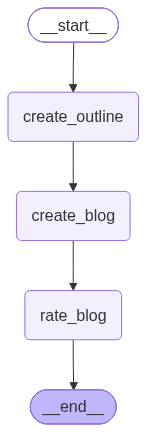

In [28]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())